# Baseline logistic regression for WTA upsets

#### Using ranking gap, surface, round, and tournament level, can we predict the chance of an upset in a 2025 WTA match?

The aim of this notebook is to build a basic model using training data from 2000-2024 that predicts whether a game is going to be an upset or not. The model will assign to each possible input a prediction probability of the match being an upset. If this prediction probability above the 50% threshold, the model will predict that it is an upset. We will test the accuracy of the model using the 2025 data as inputs.

We organise the notebook as follows.

1. Load model data from notebook 2.
2. Split earlier years for training and 2025 for testing.
3. Define numerical and categorical features.
4. One-hot encode inside a scikit-learn pipeline.
5. Train logistic regression.
6. Evaluate the model and its accuracy against the 2025 data.
7. Inspect predictions and model coefficients.
8. Conclusions and limitations.



## Producing the logistic regression model

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [3]:
model_data = pd.read_csv(
    "../data/processed/model_data_baseline.csv",
    parse_dates=["tourney_date"],
)

We define the training data as all matches occuring before 2025, and the test data the matches in 2025.

In [4]:
training_data = model_data.loc[model_data["year"] < 2025]
test_data = model_data.loc[model_data["year"] == 2025]

We use the following features for our prediction model.

In [5]:
feature_columns = ["rank_gap", "surface", "round", "tourney_level"]

Now, we focus on the testing and training data for these specified columns.

In [6]:
X_train = training_data[feature_columns]
y_train = training_data["is_upset"]

X_test = test_data[feature_columns]
y_test = test_data["is_upset"]

In order to train out model, we require that the input data is numerical. We are allowed to leave the ranking gap as it is. The categories surface, round, and tournament level are non-numerical, and hence they need to be one-hot encoded. This adds a new feature column for each possible outcome of the original category, for example there will now be a column for each of hard, grass, and clay court, and add a 1 or a 0 for each row and column according to the value of the category. We use the ColumnTransformer and OneHotEncoder from the sklearn package to do this.

In [7]:
categorical_features = ["surface", "round", "tourney_level"]

numeric_features = ["rank_gap"]

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features,
        ),
    ]
)

In [9]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("logistic_regression", LogisticRegression(max_iter=1000)),
    ]
)

In [10]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('logistic_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['rank_gap','surface','round','tourney_level']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all r

## Testing the model with 2025 data

We import metrics from the sklearn package.

In [29]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    #classification_report,
    f1_score,
    roc_auc_score,
    precision_score,
    recall_score,
)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

Here, predictions returns an array of 0-1 entries, one for each entry in the test data: 1 = predicts an upset, 0 = does not predict an upset.
Probabilites returns an array such that for each entry in the test data, there is alist in the arry of the form: [probability of not an upset, probability of an upset].

We now compare the accuracy of our model with a basline that always predicts 0.

In [26]:
# Baseline: always predict "not an upset"
baseline_predictions = np.zeros(
    len(y_test),
    dtype=int,
)

# Baseline upset probability = historical upset rate in training data
baseline_probabilities = np.full(
    len(y_test),
    y_train.mean(),
)

In [27]:
metrics_table = pd.DataFrame(
    {
        "Model": [
            "Always predict not upset",
            "Logistic regression",
        ],
        "Accuracy": [
            accuracy_score(y_test, baseline_predictions),
            accuracy_score(y_test, predictions),
        ],
        "Upset precision": [
            precision_score(
                y_test,
                baseline_predictions,
                zero_division=0,
            ),
            precision_score(
                y_test,
                predictions,
                zero_division=0,
            ),
        ],
        "Upset recall": [
            recall_score(y_test, baseline_predictions),
            recall_score(y_test, predictions),
        ],
        "Upset F1-score": [
            f1_score(
                y_test,
                baseline_predictions,
                zero_division=0,
            ),
            f1_score(
                y_test,
                predictions,
                zero_division=0,
            ),
        ],
        "ROC-AUC": [
            roc_auc_score(y_test, baseline_probabilities),
            roc_auc_score(y_test, probabilities),
        ],
    }
)

metrics_table

,Model,Accuracy,Upset precision,Upset recall,Upset F1-score,ROC-AUC
0,Always predict not upset,0.624433,0.0,0.0,0.0,0.500000
1,Logistic regression,0.624433,0.0,0.0,0.0,0.601394


We see that our model never predicts an upset, since it always chooses the common class.
Let us describe these metrics.

- Accuracy: At 62.4% because this is the rate of non-upset matches in the test data (the matches in 2025) and the model predicted all of them as being non-upsets.
- Upset recall: 0%, because the model never predicts an upset.
- F1-score: No true positives were measured because no upsets were predicted.
- ROC-AUC: This tells us whether the model gives higher probabilities to real upsets, even if none exceed 50%. This is 0.60, which is higher than the ROC-AUC for the basline model of 0.50, suggesting the logistic regression model is doing slightly better than simply guessing.

We create two figures.

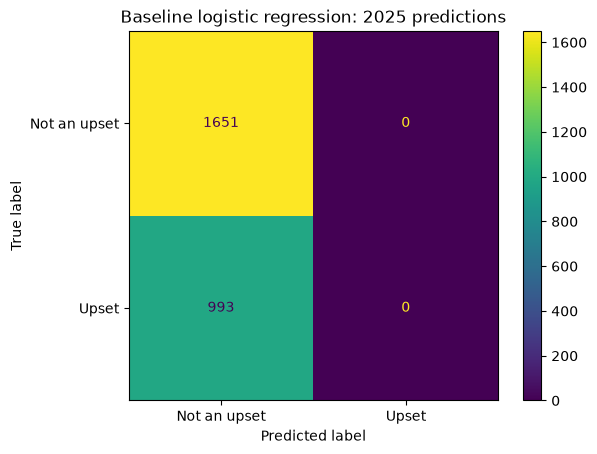

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["Not an upset", "Upset"],
)

plt.title("Baseline logistic regression: 2025 predictions")
plt.show()

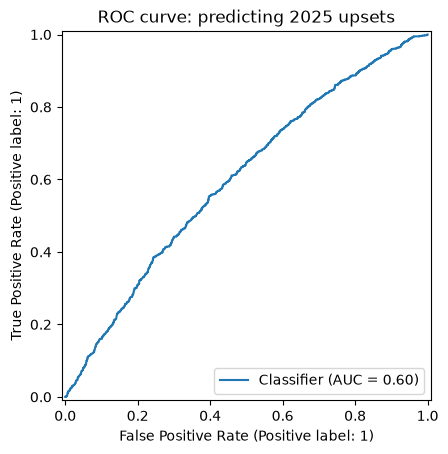

In [13]:
RocCurveDisplay.from_predictions(
    y_test,
    probabilities,
)

plt.title("ROC curve: predicting 2025 upsets")
plt.show()

## Analysing the prediction probabilities

The baseline model achieved reasonable overall accuracy by predicting the majority class, but it failed to identify any upsets at the default 50% threshold. This shows that accuracy alone is not an appropriate measure for this imbalanced prediction task. 

We instead compare the prediction probabilites, and check whether we can infer anything meaningful from these.

Our method will be as follows. 

1. Check the test entries which recieved the highest predicted upset probabilities.
2. Calculate how many of them were actual upsets.
3. Compare this to the overall upset rate.

In [15]:
results = test_data[
    [
        "tourney_date",
        "tourney_name",
        "surface",
        "round",
        "winner_name",
        "winner_rank",
        "loser_name",
        "loser_rank",
        "rank_gap",
        "is_upset",
    ]
].copy()

results["predicted_upset_probability"] = probabilities

In [31]:
top_predicted_upsets = results.sort_values(
    "predicted_upset_probability",
    ascending=False,
)

top_predicted_upsets.head(30)

,tourney_date,tourney_name,surface,round,winner_name,winner_rank,loser_name,loser_rank,rank_gap,is_upset,predicted_upset_probability
51860,2025-06-16,Nottingham,Grass,F,Mccartney Kessler,42,Dayana Yastremska,46,4,0,0.461481
51919,2025-06-23,Eastbourne,Grass,SF,Maya Joint,51,Anastasia Pavlyuchenkova,53,2,0,0.456437
51804,2025-06-09,s Hertogenbosch,Grass,R32,Anna Blinkova,70,Katerina Siniakova,73,3,0,0.456387
51861,2025-06-16,Nottingham,Grass,SF,Mccartney Kessler,42,Rebecca Sramkova,38,4,1,0.454736
51878,2025-06-16,Nottingham,Grass,R32,Katie Boulter,39,Lulu Sun,44,5,0,0.454687
51565,2025-05-06,Rome,Clay,R128,Victoria Azarenka,54,Camila Osorio,55,1,0,0.454121
51581,2025-05-06,Rome,Clay,R128,Suzan Lamens,71,Renata Zarazua,69,2,1,0.453271
51471,2025-04-22,Madrid,Clay,R128,Veronika Kudermetova,52,Polina Kudermetova,54,2,0,0.453271
51777,2025-06-09,s Hertogenbosch,Grass,SF,Elise Mertens,25,Ekaterina Alexandrova,19,6,1,0.453037
51577,2025-05-06,Rome,Clay,R128,Rebecca Sramkova,41,Mccartney Kessler,44,3,0,0.452422


In [32]:
top_n = 30

top_matches = results.nlargest(
    top_n,
    "predicted_upset_probability",
)

print(
    f"Upset rate among top {top_n} predictions: "
    f"{top_matches['is_upset'].mean():.1%}"
)

print(
    f"Overall 2025 upset rate: "
    f"{results['is_upset'].mean():.1%}"
)

Upset rate among top 30 predictions: 50.0%
Overall 2025 upset rate: 37.6%


In [33]:
top_upset_rate = top_matches["is_upset"].mean()
overall_upset_rate = results["is_upset"].mean()

print(
    f"Top-{top_n} lift: "
    f"{top_upset_rate / overall_upset_rate:.2f}×"
)

Top-30 lift: 1.33×


This tells us that the top 30 predicted matches contained 1.33x more real upsets than normal.

## Findings


### Conclusions

- None of the matches were predicted an upset probability above the threshold of 50%.

- The 30 matches with the highest upset prediction probabilities contained 1.33x more real upsets on average than the overall rate; 50% of the top 30 matches were real upsets, compared with 37.6% overall.

- The logistic regression model had a ROC-AUC of 0.60, higher than the baseline 0-model (always predicting an upset) that has an ROC-AUC of 0.5. This suggests the model assigned a higher probability of an upset to matches that were real upsets than on average.


### Limitations

- The model uses only ranking gap, court surface, tournament round, and
  tournament level. It does not include player form, injuries, head-to-head
  records, recent workload, or surface-specific performance.

- Matches with missing rankings and walkovers were excluded. This may mean
  that the analysed matches are not perfectly representative of all WTA
  matches.

- The disrupted 2020 season was excluded from modelling. This makes the
  training data more representative of typical seasons, but reduces the
  amount of available historical data.

- Upsets are the minority outcome. As a result, a model can achieve reasonable
  accuracy by predicting no upset for every match, so accuracy alone is not a
  sufficient evaluation measure.

- The baseline model did not predict any upsets at the default 50% threshold.
  Although its probability rankings may still contain useful information, it
  is not yet suitable as a direct yes/no upset predictor.

### Next steps

- Add more features to the model, such as recent individual player data and current form.

- Compare the logistic-regression baseline with more flexible models, for example lowering the upset threshold.